In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
df = pd.read_csv('/content/Titanic-Dataset.csv')
df = df[['Fare','Pclass','Age','SibSp','Parch']]
df['Age'] = df['Age'].fillna(df['Age'].median())
df = df[df['Fare']>0]

In [4]:
X_simple = df[['Pclass']]
y = df['Fare']
X_tr,X_te,y_tr,y_te = train_test_split(X_simple,y,test_size=0.2,random_state=42)
model_simple = LinearRegression().fit(X_tr,y_tr)
pred_simple = model_simple.predict(X_te)
print('Simple Regression -- Intercept:',round(model_simple.intercept_,2))
print('Simple Regression -- Slope:',round(model_simple.coef_[0],2))
print('Simple Regression -- R2:',round(r2_score(y_te,pred_simple),2))
print('Simple Regression -- RMSE:',round(np.sqrt(mean_squared_error(y_te,pred_simple)),2))

Simple Regression -- Intercept: 112.38
Simple Regression -- Slope: -34.23
Simple Regression -- R2: 0.37
Simple Regression -- RMSE: 35.68


In [7]:
X_multi = df[['Pclass','Age','SibSp','Parch']]
X_tr2,X_te2,y_tr2,y_te2 = train_test_split(X_multi,y,test_size=0.2,random_state=42)
model_multi = LinearRegression().fit(X_tr2,y_tr2)
pred_multi = model_multi.predict(X_te2)
print('\nMultiple Regression -- Intercept:',round(model_multi.intercept_,2))
for name,coef in zip(X_multi.columns,model_multi.coef_):
  print('Multiple Regression --Coefficient of',name,':',round(coef,2))
print('Multiple Regression -- R2:',round(r2_score(y_te2,pred_multi),2))
print('Multiple Regression -- RMSE:',round(np.sqrt(mean_squared_error(y_te2,pred_multi)),2))


Multiple Regression -- Intercept: 112.3
Multiple Regression --Coefficient of Pclass : -35.72
Multiple Regression --Coefficient of Age : -0.12
Multiple Regression --Coefficient of SibSp : 5.38
Multiple Regression --Coefficient of Parch : 10.09
Multiple Regression -- R2: 0.46
Multiple Regression -- RMSE: 33.0


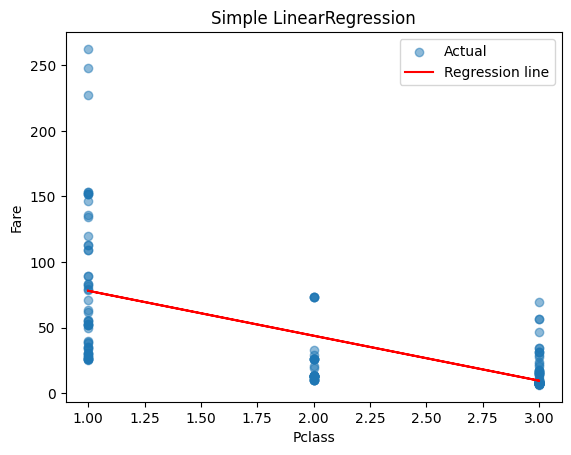

In [8]:
plt.scatter(X_te,y_te,alpha=0.5,label='Actual')
plt.plot(X_te,pred_simple,color='red',label='Regression line')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.title('Simple LinearRegression')
plt.legend()
plt.show()

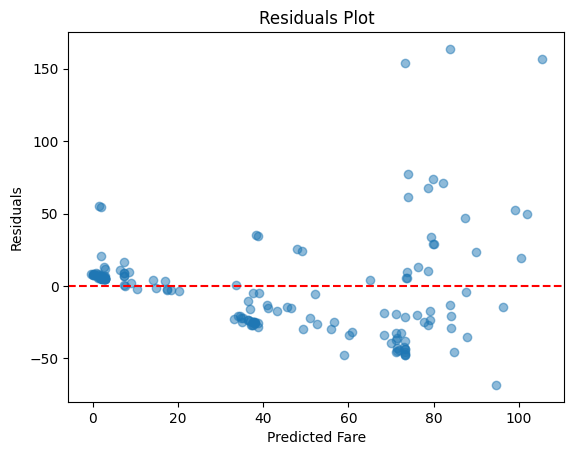

In [9]:
residuals = y_te2 - pred_multi
plt.scatter(pred_multi,residuals,alpha=0.5)
plt.axhline(0,color='red',linestyle='--')
plt.xlabel('Predicted Fare')
plt.ylabel('Residuals')
plt.title('Residuals Plot')
plt.show()

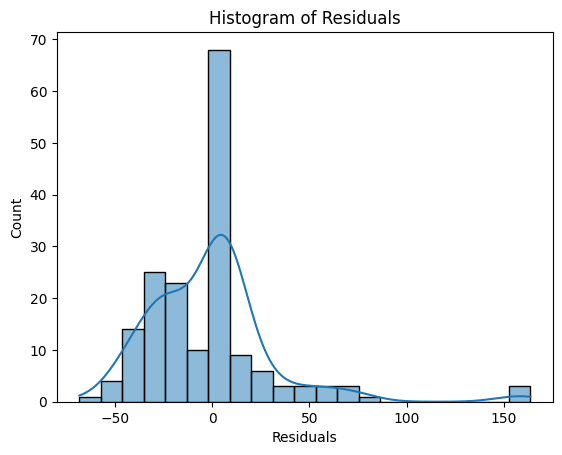

In [12]:
sns.histplot(residuals,kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals')
plt.show()

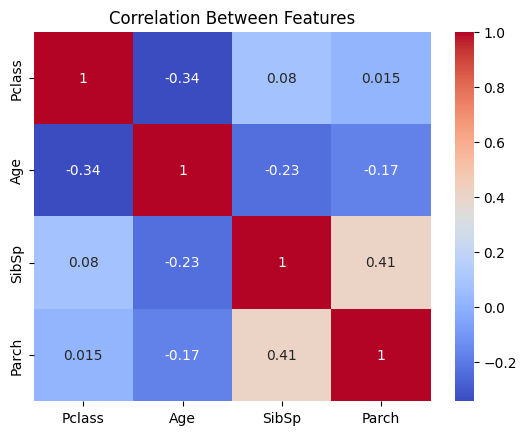

In [13]:
sns.heatmap(X_multi.corr(),annot=True,cmap='coolwarm')
plt.title('Correlation Between Features')
plt.show()